In [1]:
import os
import pandas as pd

# =========================
# PATHS
# =========================

dbcan_file = "../results/dbcan_hits/dbcan_hits.txt"

species_map = pd.read_csv(
    "../results/signalp_fast_slow/protein_species_map.csv"
)


In [2]:
all_hits = []

with open(dbcan_file) as f:

    for line in f:

        if line.startswith("#"):
            continue

        parts = line.strip().split()

        if len(parts) < 23:
            continue

        target = parts[0]

        tlen = int(parts[2])

        query = parts[3]

        evalue = float(parts[12])

        score = float(parts[13])

        hmm_from = int(parts[15])
        hmm_to   = int(parts[16])

        ali_from = int(parts[17])
        ali_to   = int(parts[18])

        coverage = (
            (hmm_to - hmm_from + 1)
            / tlen
        )

        all_hits.append({

            "query": query,

            "family": target.replace(".hmm", ""),

            "tlen": tlen,

            "evalue": evalue,
            "score": score,

            "hmm_from": hmm_from,
            "hmm_to": hmm_to,

            "ali_from": ali_from,
            "ali_to": ali_to,

            "coverage": coverage
        })

hits = pd.DataFrame(all_hits)

In [3]:
hits

,query,family,tlen,evalue,score,hmm_from,hmm_to,ali_from,ali_to,coverage
0,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16_19,174,4.500000e-73,240.1,2,174,99,272,0.994253
1,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16_18,158,1.100000e-45,150.7,18,158,124,269,0.892405
2,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16_21,207,2.600000e-24,81.6,54,188,118,258,0.652174
3,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16,189,8.600000e-23,77.6,33,184,104,272,0.804233
4,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,GH16_20,163,1.600000e-17,59.4,4,154,108,259,0.926380
...,...,...,...,...,...,...,...,...,...,...
59367,tr|Q6CCD3|Q6CCD3_YARLI,GH132,303,1.800000e+02,-3.2,10,32,385,406,0.075908
59368,tr|Q6CCD3|Q6CCD3_YARLI,GH132,303,1.300000e+01,0.6,11,79,592,661,0.227723
59369,tr|Q6CDY0|Q6CDY0_YARLI,CE1,227,3.000000e-03,13.0,85,147,172,232,0.277533
59370,tr|Q6CHB8|Q6CHB8_YARLI,CE1,227,1.100000e-02,11.3,86,125,182,218,0.176211


In [4]:
species_map

,protein,species
0,tr|A0A1L9U2J4|A0A1L9U2J4_ASPBC,aspergillus_brasiliensis
1,tr|A0A1L9U2T6|A0A1L9U2T6_ASPBC,aspergillus_brasiliensis
2,tr|A0A1L9U5R7|A0A1L9U5R7_ASPBC,aspergillus_brasiliensis
3,tr|A0A1L9U6P4|A0A1L9U6P4_ASPBC,aspergillus_brasiliensis
4,tr|A0A1L9U6P8|A0A1L9U6P8_ASPBC,aspergillus_brasiliensis
...,...,...
23412,tr|Q6CI94|Q6CI94_YARLI,yarrowia_lipolytica
23413,tr|Q6CIA5|Q6CIA5_YARLI,yarrowia_lipolytica
23414,tr|Q6CIA6|Q6CIA6_YARLI,yarrowia_lipolytica
23415,tr|W0TYL8|W0TYL8_YARLI,yarrowia_lipolytica


In [5]:
hits = (
    hits
    .merge(
        species_map,
        left_on="query",
        right_on="protein",
        how="left"
    )
    .drop(columns="protein")
)

print(
    "Proteins without species:",
    hits["species"].isna().sum()
)

Proteins without species: 0


In [6]:
hits.describe()

,tlen,evalue,score,hmm_from,hmm_to,ali_from,ali_to,coverage
count,59372.000000,5.937200e+04,59372.000000,59372.000000,59372.000000,59372.000000,59372.000000,59372.000000
mean,336.121539,1.886874e+01,69.296788,84.550394,227.342720,179.970121,329.223725,0.474520
std,170.377771,8.511125e+01,117.754595,115.578661,139.651577,180.731406,194.781980,0.336633
min,21.000000,0.000000e+00,-213.700000,1.000000,2.000000,2.000000,14.000000,0.002532
25%,233.000000,6.975000e-22,9.900000,4.000000,128.000000,59.000000,212.000000,0.164179
50%,301.000000,3.600000e-07,25.500000,29.000000,203.000000,110.000000,287.000000,0.387821
75%,411.000000,1.900000e-02,73.700000,129.000000,297.000000,248.000000,389.000000,0.828194
max,1392.000000,8.800000e+02,1198.600000,1123.000000,1256.000000,2408.000000,2429.000000,1.000000


In [7]:
print(f"Raw HMM hits: {len(hits):,}")
print(f"Unique proteins: {hits['query'].nunique():,}")
print(f"Species represented: {hits['species'].nunique()}")

Raw HMM hits: 59,372
Unique proteins: 7,449
Species represented: 29


In [8]:
hits["family"].value_counts().head(20)

family
CBM1       802
CBM18      664
AA7        647
CBM50      625
AA3_4      592
AA3_1      556
AA3_3      550
AA9        446
CE1        432
GH5        428
GH43_18    375
PL44       353
GH43_33    351
AA5        345
GH43_1     342
GH117      336
GH158      333
GH5_19     331
GH16_6     326
GH18       326
Name: count, dtype: int64

In [9]:
hits["query"].nunique()

7449

In [10]:
# =========================
# INITIAL FILTERING
# =========================

hits = hits[
    (hits["evalue"] < 1e-15) &
    (hits["coverage"] >= 0.35)
].copy()

hits["class"] = hits["family"].str.extract(
    r"^(GH|GT|PL|CE|AA|CBM)"
)

print(hits.shape)

(17662, 12)


In [11]:
hits.columns

Index(['query', 'family', 'tlen', 'evalue', 'score', 'hmm_from', 'hmm_to',
       'ali_from', 'ali_to', 'coverage', 'species', 'class'],
      dtype='str')

In [12]:
def filter_overlapping_domains(
    df,
    overlap_threshold=0.2
):

    filtered_rows = []

    for protein, group in df.groupby(["species", "query"]):

        group = group.sort_values(
            "score",
            ascending=False
        )

        kept = []

        for _, row in group.iterrows():

            start = row["ali_from"]
            end = row["ali_to"]

            overlap = False

            for kept_row in kept:

                s2 = kept_row["ali_from"]
                e2 = kept_row["ali_to"]

                overlap_len = max(
                    0,
                    min(end, e2) - max(start, s2)
                )

                length = end - start

                if overlap_len / length > overlap_threshold:
                    overlap = True
                    break

            if not overlap:
                kept.append(row)

        filtered_rows.extend(kept)

    return pd.DataFrame(filtered_rows)

In [13]:
def merge_same_family_domains(
    df,
    max_gap=40
):

    merged_rows = []

    for protein, group in df.groupby(["species", "query"]):

        group = group.sort_values("ali_from")

        current = None

        for _, row in group.iterrows():

            if current is None:
                current = row.copy()
                continue

            same_family = (
                row["family"] == current["family"]
            )

            gap = (
                row["ali_from"] -
                current["ali_to"]
            )

            if same_family and gap <= max_gap:

                current["ali_to"] = max(
                    current["ali_to"],
                    row["ali_to"]
                )

            else:
                merged_rows.append(current)
                current = row.copy()

        if current is not None:
            merged_rows.append(current)

    return pd.DataFrame(merged_rows)

In [14]:
hits_filtered = filter_overlapping_domains(hits)

hits_merged = merge_same_family_domains(
    hits_filtered
)

print(len(hits))
print(len(hits_filtered))
print(len(hits_merged))

17662
6363
6315


In [15]:
hits_filtered["query"].nunique()

5971

In [16]:
hits_merged["query"].nunique()

5971

In [17]:
architecture_df = (
    hits_merged
    .sort_values(
        ["species", "query", "ali_from"]
    )
    .groupby(
        ["species", "query"]
    )["family"]
    .apply(list)
    .reset_index()
)

architecture_df["domain_architecture"] = (
    architecture_df["family"]
    .apply(lambda x: " + ".join(x))
)

architecture_df["domain_count"] = (
    architecture_df["family"]
    .apply(len)
)

architecture_df.head()

,species,query,family,domain_architecture,domain_count
0,aspergillus_brasiliensis,tr|A0A1L9U1H8|A0A1L9U1H8_ASPBC,[AA11],AA11,1
1,aspergillus_brasiliensis,tr|A0A1L9U269|A0A1L9U269_ASPBC,[AA7],AA7,1
2,aspergillus_brasiliensis,tr|A0A1L9U287|A0A1L9U287_ASPBC,[AA1],AA1,1
3,aspergillus_brasiliensis,tr|A0A1L9U297|A0A1L9U297_ASPBC,[CE8],CE8,1
4,aspergillus_brasiliensis,tr|A0A1L9U2C6|A0A1L9U2C6_ASPBC,[GH3],GH3,1


In [18]:
architecture_df[
    "domain_architecture"
].value_counts().head(20)

domain_architecture
AA7        367
AA9        273
GH18       264
GH28       210
GH3        203
AA3_2      159
CE5        110
CE4        103
GH11        97
GH72        82
AA11        81
GH92        80
CE1         78
GH55_2      78
GH7         77
GH16_18     72
GH31_1      71
GH27        71
GH16_1      71
GH128       69
Name: count, dtype: int64

In [19]:
multi = architecture_df[
    architecture_df["domain_count"] >= 2
]

multi.sort_values(
    "domain_count",
    ascending=False
)

,species,query,family,domain_architecture,domain_count
2208,fusarium_graminearum,tr|A0A098DKH5|A0A098DKH5_GIBZE,"[CE8, CE8, CE8, CE8, CE8]",CE8 + CE8 + CE8 + CE8 + CE8,5
319,aspergillus_clavatus,tr|A1C8R7|A1C8R7_ASPCL,"[CE8, CE8, CE8, CE8]",CE8 + CE8 + CE8 + CE8,4
1599,aspergillus_terreus,tr|A0A5M3YUF2|A0A5M3YUF2_ASPTE,"[GH79, CBM67, GH78]",GH79 + CBM67 + GH78,3
655,aspergillus_japonicus,tr|A0A8T8WKZ6|A0A8T8WKZ6_ASPJA,"[CE8, CE8, CE8]",CE8 + CE8 + CE8,3
626,aspergillus_fumigatus,tr|B0YAL6|B0YAL6_ASPFC,"[CE8, CE8, CE8]",CE8 + CE8 + CE8,3
...,...,...,...,...,...
422,aspergillus_clavatus,tr|A1CU83|A1CU83_ASPCL,"[GH72, CBM43]",GH72 + CBM43,2
441,aspergillus_fumigatus,sp|B0XT09|GEL3_ASPFC,"[GH72, CBM43]",GH72 + CBM43,2
447,aspergillus_fumigatus,sp|B0XVI5|GEL4_ASPFC,"[GH72, CBM43]",GH72 + CBM43,2
465,aspergillus_fumigatus,sp|B0Y8K2|CBHB_ASPFC,"[GH7, CBM1]",GH7 + CBM1,2


In [20]:
architecture_df["domain_architecture"].value_counts().head(50)

domain_architecture
AA7             367
AA9             273
GH18            264
GH28            210
GH3             203
AA3_2           159
CE5             110
CE4             103
GH11             97
GH72             82
AA11             81
GH92             80
CE1              78
GH55_2           78
GH7              77
GH16_18          72
GH31_1           71
GH27             71
GH16_1           71
GH128            69
AA1              66
CE16             66
GH71             65
GH5_5            65
GH10             63
GH12             63
GH35             59
GH13_1           59
CE8              58
PL1_4            56
GH76             55
AA1_3            53
CE3              53
GH75             51
GH20             51
GH47             49
GH72 + CBM43     48
GH17             47
GH132            47
GH79             47
GH5_7            46
GH43_6           45
GH78             45
GH62             44
GH93             41
CE12             39
GH6              39
PL3_2            38
GH32             36


In [21]:
architecture_df["domain_architecture"].nunique()

252

In [22]:
species_per_arch = (
    architecture_df
    .groupby("domain_architecture")["species"]
    .nunique()
    .sort_values(ascending=False)
)
species_per_arch.head(20)

domain_architecture
GH3        29
GH72       29
GH16_19    28
GH16_1     28
GH20       28
GH47       28
GH31_1     28
GH18       28
AA7        27
CE16       27
CE8        27
CE4        27
GH13_1     27
GH128      27
GH16_18    27
GH28       27
GH7        27
AA9        27
AA3_2      27
GH11       27
Name: species, dtype: int64

In [23]:
multi["domain_architecture"].value_counts().head(50)

domain_architecture
GH72 + CBM43                   48
GH71 + CBM24                   34
GH15 + CBM20                   30
GH54 + CBM42                   28
AA8 + AA3_1                    27
GH43_14 + CBM91                19
GH13_1 + CBM20                 16
GH43_36 + CBM91                13
GH55_2 + GH55_2                11
GH7 + CBM1                     11
GH43_29 + CBM6                  9
GH10 + CBM1                     6
GH43_13 + CBM91                 6
AA13 + CBM20                    5
GH5_4 + CBM46                   5
GH32 + CBM38                    4
GH5_5 + CBM1                    4
CBM35 + GH26                    4
CE8 + GH28                      4
CBM87 + CE18                    3
AA1 + AA1                       3
GH18 + CBM24                    3
GH43_34 + CBM66                 3
CE8 + CE8 + CE8                 2
GH142 + CBM13                   2
CBM38 + GH32                    2
GH18 + CBM19                    2
GH76 + CBM13                    2
CE8 + CE8 + CE8 + CE8       

In [24]:
multi["domain_architecture"].nunique()

55

In [25]:
species_per_multi_arch = (
    multi
    .groupby("domain_architecture")["species"]
    .nunique()
    .sort_values(ascending=False)
)
species_per_multi_arch.head(50)

domain_architecture
GH72 + CBM43                   23
GH15 + CBM20                   20
GH54 + CBM42                   19
GH71 + CBM24                   19
AA8 + AA3_1                    15
GH13_1 + CBM20                 14
GH43_14 + CBM91                14
GH55_2 + GH55_2                11
GH43_36 + CBM91                 9
GH43_29 + CBM6                  8
GH7 + CBM1                      7
GH43_13 + CBM91                 6
GH10 + CBM1                     6
AA13 + CBM20                    5
GH5_4 + CBM46                   5
GH32 + CBM38                    4
CBM35 + GH26                    4
CE8 + GH28                      4
GH18 + CBM24                    3
CBM87 + CE18                    3
GH43_34 + CBM66                 3
GH5_5 + CBM1                    3
AA1 + AA1                       3
GH76 + CBM13                    2
CBM38 + GH32                    2
GH142 + CBM13                   2
GH18 + CBM19                    2
CE8 + CE8 + CE8                 2
GH13_1 + GH13_5             

In [26]:
   is_homomeric = multi["domain_architecture"].map(
       lambda arch: len(set(arch.split(" + "))) == 1
   )
   multi_hetero = multi[~is_homomeric]

In [27]:
multi_hetero["domain_architecture"].value_counts().head(50)

domain_architecture
GH72 + CBM43            48
GH71 + CBM24            34
GH15 + CBM20            30
GH54 + CBM42            28
AA8 + AA3_1             27
GH43_14 + CBM91         19
GH13_1 + CBM20          16
GH43_36 + CBM91         13
GH7 + CBM1              11
GH43_29 + CBM6           9
GH10 + CBM1              6
GH43_13 + CBM91          6
AA13 + CBM20             5
GH5_4 + CBM46            5
GH32 + CBM38             4
GH5_5 + CBM1             4
CBM35 + GH26             4
CE8 + GH28               4
CBM87 + CE18             3
GH18 + CBM24             3
GH43_34 + CBM66          3
GH142 + CBM13            2
CBM38 + GH32             2
GH18 + CBM19             2
GH76 + CBM13             2
GH13_1 + GH13_5          1
GH55 + GH55_2            1
GH79 + CBM67 + GH78      1
GH93 + CBM66             1
GH30_7 + GH30            1
GH43_26 + CBM42          1
AA1_3 + AA1              1
GH13_32 + CBM20          1
AA9 + CBM1               1
CBM1 + GH10              1
CE1 + CBM1               1
GH18 + C

In [28]:
multi_hetero["domain_architecture"].nunique()

47

In [29]:
species_per_multi_hetero_arch = (
    multi_hetero
    .groupby("domain_architecture")["species"]
    .nunique()
    .sort_values(ascending=False)
)
species_per_multi_hetero_arch.head(50)

domain_architecture
GH72 + CBM43            23
GH15 + CBM20            20
GH54 + CBM42            19
GH71 + CBM24            19
AA8 + AA3_1             15
GH13_1 + CBM20          14
GH43_14 + CBM91         14
GH43_36 + CBM91          9
GH43_29 + CBM6           8
GH7 + CBM1               7
GH10 + CBM1              6
GH43_13 + CBM91          6
GH5_4 + CBM46            5
AA13 + CBM20             5
CBM35 + GH26             4
CE8 + GH28               4
GH32 + CBM38             4
GH43_34 + CBM66          3
CBM87 + CE18             3
GH18 + CBM24             3
GH5_5 + CBM1             3
GH76 + CBM13             2
GH142 + CBM13            2
CBM38 + GH32             2
GH18 + CBM19             2
CE1 + CBM1               1
AA1_3 + AA1              1
AA2 + AA5                1
AA9 + CBM1               1
CBM1 + GH10              1
CBM1 + GH45_1            1
GH128 + GH16_4           1
GH11 + CBM1              1
GH30_7 + GH30            1
GH27 + GH28              1
GH13_32 + CBM20          1
GH13_1 +

In [30]:
arch_species = pd.crosstab(
    multi_hetero["domain_architecture"],
    multi_hetero["species"]
)
arch_species.sum(axis=1)

domain_architecture
AA13 + CBM20             5
AA1_3 + AA1              1
AA2 + AA5                1
AA8 + AA3_1             27
AA9 + CBM1               1
CBM1 + GH10              1
CBM1 + GH45_1            1
CBM35 + GH26             4
CBM38 + GH32             2
CBM87 + CE18             3
CE1 + CBM1               1
CE8 + GH28               4
GH10 + CBM1              6
GH11 + CBM1              1
GH128 + GH16_4           1
GH13_1 + CBM20          16
GH13_1 + GH13_5          1
GH13_32 + CBM20          1
GH142 + CBM13            2
GH15 + CBM20            30
GH18 + CBM19             2
GH18 + CBM24             3
GH18 + CBM5              1
GH27 + GH28              1
GH30_7 + GH30            1
GH32 + CBM38             4
GH32 + CBM38 + GH32      1
GH43_13 + CBM91          6
GH43_14 + CBM91         19
GH43_26 + CBM42          1
GH43_29 + CBM6           9
GH43_34 + CBM66          3
GH43_36 + CBM91         13
GH45_2 + CBM1            1
GH54 + CBM42            28
GH55 + GH55_2            1
GH5_4 + 

In [31]:
# Most common architectures (protein count)
arch_counts = (
    multi_hetero["domain_architecture"]
    .value_counts()
)

common = arch_counts[arch_counts >= 3]

other_count = arch_counts[arch_counts < 3].sum()

arch_counts_plot = pd.concat([
    common,
    pd.Series({"Other rare architectures": other_count})
])

<Axes: >

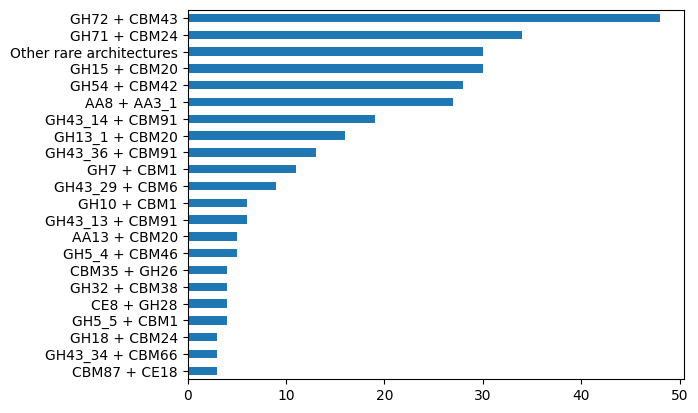

In [32]:
arch_counts_plot.sort_values().plot.barh()

<Axes: >

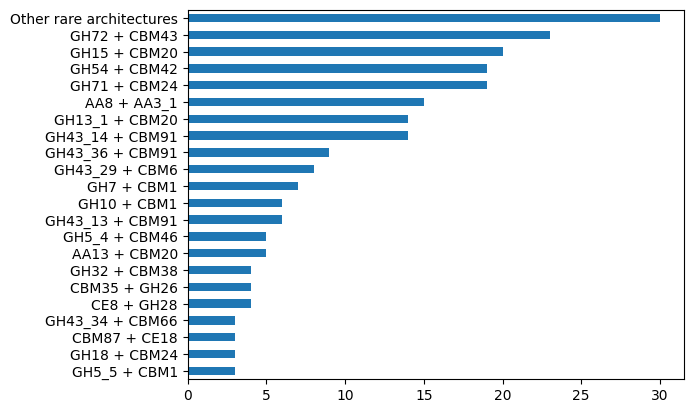

In [33]:
# Most widespread architectures (species count)
common_spec = species_per_multi_hetero_arch[species_per_multi_hetero_arch >= 3]

other_count_spec = species_per_multi_hetero_arch[species_per_multi_hetero_arch < 3].sum()

species_counts_plot = pd.concat([
    common_spec,
    pd.Series({"Other rare architectures": other_count_spec})
])
species_counts_plot.sort_values().plot.barh()

In [34]:
#Which architectures are relevant to biomass degradation?

In [35]:
cellulose_arch = multi_hetero[
    multi_hetero["domain_architecture"]
    .str.contains("CBM")
]

In [36]:
cellulose_arch["domain_architecture"].value_counts()

domain_architecture
GH72 + CBM43            48
GH71 + CBM24            34
GH15 + CBM20            30
GH54 + CBM42            28
GH43_14 + CBM91         19
GH13_1 + CBM20          16
GH43_36 + CBM91         13
GH7 + CBM1              11
GH43_29 + CBM6           9
GH10 + CBM1              6
GH43_13 + CBM91          6
AA13 + CBM20             5
GH5_4 + CBM46            5
GH32 + CBM38             4
GH5_5 + CBM1             4
CBM35 + GH26             4
CBM87 + CE18             3
GH18 + CBM24             3
GH43_34 + CBM66          3
GH142 + CBM13            2
CBM38 + GH32             2
GH18 + CBM19             2
GH76 + CBM13             2
GH79 + CBM67 + GH78      1
GH93 + CBM66             1
GH43_26 + CBM42          1
GH13_32 + CBM20          1
AA9 + CBM1               1
CBM1 + GH10              1
CE1 + CBM1               1
GH18 + CBM5              1
CBM1 + GH45_1            1
GH71 + CBM24 + CBM24     1
GH45_2 + CBM1            1
GH32 + CBM38 + GH32      1
GH11 + CBM1              1
GH74 + G

In [37]:
cellulose_arch["domain_architecture"].nunique()

37

In [38]:
'''architecture_summary = pd.DataFrame({
    "proteins": multi_hetero["domain_architecture"].value_counts(),
    "species": species_per_multi_hetero_arch
}).reset_index()

architecture_summary.columns = [
    "architecture",
    "proteins",
    "species"
]

architecture_summary = architecture_summary.sort_values(
    "proteins",
    ascending=False
)

architecture_summary.head()'''

'architecture_summary = pd.DataFrame({\n    "proteins": multi_hetero["domain_architecture"].value_counts(),\n    "species": species_per_multi_hetero_arch\n}).reset_index()\n\narchitecture_summary.columns = [\n    "architecture",\n    "proteins",\n    "species"\n]\n\narchitecture_summary = architecture_summary.sort_values(\n    "proteins",\n    ascending=False\n)\n\narchitecture_summary.head()'

In [39]:
multi_hetero

,species,query,family,domain_architecture,domain_count
10,aspergillus_brasiliensis,tr|A0A1L9U2T6|A0A1L9U2T6_ASPBC,"[GH15, CBM20]",GH15 + CBM20,2
19,aspergillus_brasiliensis,tr|A0A1L9U3B6|A0A1L9U3B6_ASPBC,"[GH32, CBM38]",GH32 + CBM38,2
25,aspergillus_brasiliensis,tr|A0A1L9U3Z0|A0A1L9U3Z0_ASPBC,"[GH72, CBM43]",GH72 + CBM43,2
52,aspergillus_brasiliensis,tr|A0A1L9U833|A0A1L9U833_ASPBC,"[AA8, AA3_1]",AA8 + AA3_1,2
86,aspergillus_brasiliensis,tr|A0A1L9UBN9|A0A1L9UBN9_ASPBC,"[GH54, CBM42]",GH54 + CBM42,2
...,...,...,...,...,...
5870,trichoderma_virens,tr|G9N056|G9N056_HYPVG,"[GH43_13, CBM91]",GH43_13 + CBM91,2
5881,trichoderma_virens,tr|G9N0W8|G9N0W8_HYPVG,"[GH72, CBM43]",GH72 + CBM43,2
5890,trichoderma_virens,tr|G9N1C8|G9N1C8_HYPVG,"[GH72, CBM43]",GH72 + CBM43,2
5952,yarrowia_lipolytica,tr|Q6C863|Q6C863_YARLI,"[GH18, CBM19]",GH18 + CBM19,2


In [40]:
architecture_summary = (
    multi_hetero
    .groupby("domain_architecture")
    .agg(
        proteins=("query", "count"),
        species=("species", "nunique")
    )
    .reset_index()
)

architecture_summary.columns = [
    "domain_architecture",
    "proteins",
    "species"
]



In [41]:
architecture_summary

,domain_architecture,proteins,species
0,AA13 + CBM20,5,5
1,AA1_3 + AA1,1,1
2,AA2 + AA5,1,1
3,AA8 + AA3_1,27,15
4,AA9 + CBM1,1,1
5,CBM1 + GH10,1,1
6,CBM1 + GH45_1,1,1
7,CBM35 + GH26,4,4
8,CBM38 + GH32,2,2
9,CBM87 + CE18,3,3


In [42]:
thermophiles = [
    "myceliophthora_thermophila",
    "thielavia_terrestris",
    "chaetomium_thermophilum"
]

thermo_counts = (
    multi_hetero[
        multi_hetero["species"].isin(thermophiles)
    ]
    .groupby("domain_architecture")["species"]
    .nunique()
    .reset_index(name="thermophile_species")
)

architecture_summary = architecture_summary.merge(
    thermo_counts,
    on="domain_architecture",
    how="left"
)

architecture_summary["thermophile_species"] = (
    architecture_summary["thermophile_species"]
    .fillna(0)
    .astype(int)
)

architecture_summary = architecture_summary.sort_values(
    ["proteins", "species"],
    ascending=False
)

architecture_summary.sort_values("thermophile_species", ascending=False).head(30)

,domain_architecture,proteins,species,thermophile_species
3,AA8 + AA3_1,27,15,3
28,GH43_14 + CBM91,19,14,2
19,GH15 + CBM20,30,20,2
15,GH13_1 + CBM20,16,14,2
12,GH10 + CBM1,6,6,2
38,GH7 + CBM1,11,7,2
32,GH43_36 + CBM91,13,9,2
7,CBM35 + GH26,4,4,2
34,GH54 + CBM42,28,19,1
41,GH72 + CBM43,48,23,1


In [43]:
interesting_arch = [
    "GH7 + CBM1",
    "GH10 + CBM1",
    "GH5_4 + CBM46",
    "AA9 + CBM1",
    "GH45_2 + CBM1",
    "GH74 + GH74 + CBM1"
]

candidates = multi_hetero[
    multi_hetero["domain_architecture"].isin(
        interesting_arch
    )
]

In [44]:
candidates[
    [
        "species",
        "query",
        "domain_architecture"
    ]
].sort_values(
    ["domain_architecture","species"]
)

,species,query,domain_architecture
4105,podospora_anserina,sp|B2B629|LP9A_PODAN,AA9 + CBM1
488,aspergillus_fumigatus,tr|B0XM69|B0XM69_ASPFC,GH10 + CBM1
1049,aspergillus_nidulans,tr|Q5AWC9|Q5AWC9_EMENI,GH10 + CBM1
2892,myceliophthora_thermophila,tr|G2QJ91|G2QJ91_THET4,GH10 + CBM1
4197,podospora_anserina,tr|B2AFS1|B2AFS1_PODAN,GH10 + CBM1
4679,talaromyces_amestolkiae,tr|A0A364LCP8|A0A364LCP8_TALAM,GH10 + CBM1
5037,thielavia_terrestris,tr|G2R5G6|G2R5G6_THETT,GH10 + CBM1
4678,talaromyces_amestolkiae,tr|A0A364LCP0|A0A364LCP0_TALAM,GH45_2 + CBM1
571,aspergillus_fumigatus,tr|B0Y1Z4|B0Y1Z4_ASPFC,GH5_4 + CBM46
1786,aspergillus_terreus,tr|A0A5M3ZGE8|A0A5M3ZGE8_ASPTE,GH5_4 + CBM46


In [45]:
import re

CELLULOSE     = {"GH5", "GH6", "GH7", "GH12", "GH45", "AA9"}
HEMICELLULOSE = {"GH10", "GH11", "GH26", "GH27", "GH43", "GH54",
                 "GH62", "GH67", "GH74", "GH115", "CE1"}
PECTIN        = {"GH28", "GH78", "GH79", "GH93", "CE8"}
OXIDATIVE     = {"AA1", "AA2", "AA3", "AA5", "AA8", "AA13"}
FUNGAL_WALL   = {"GH16", "GH18", "GH55", "GH71", "GH72", "GH76", "GH128"}

GROUPS = [
    ("Cellulose", CELLULOSE),
    ("Hemicellulose", HEMICELLULOSE),
    ("Pectin", PECTIN),
    ("Oxidative (AA)", OXIDATIVE),
    ("Fungal cell wall & chitin", FUNGAL_WALL),
]

def families(architecture):
    """'GH5_4 + CBM46' -> {'GH5', 'CBM46'} (subfamily numbers dropped)."""
    return set(re.findall(r"[A-Z]+\d+", architecture))

def functional_group(architecture):
    fams = families(architecture)
    for name, members in GROUPS:
        if fams & members:
            return name
    return "Starch, fructan & other"

architecture_summary["has_cbm"] = (
    architecture_summary["domain_architecture"]
    .str.contains("CBM")
)
architecture_summary["functional_group"] = (
    architecture_summary["domain_architecture"].map(functional_group)
)
architecture_summary["has_cellulase"] = (
    architecture_summary["functional_group"] == "Cellulose"
)
architecture_summary["plant_cell_wall"] = (
    architecture_summary["functional_group"].isin(
        ["Cellulose", "Hemicellulose", "Pectin"]
    )
)

# "Biomass" = plant cell wall: cellulose, hemicellulose and pectin
biomass_arch = architecture_summary[
    architecture_summary["plant_cell_wall"]
]

In [46]:
biomass_arch

,domain_architecture,proteins,species,thermophile_species,has_cbm,functional_group,has_cellulase,plant_cell_wall
34,GH54 + CBM42,28,19,1,True,Hemicellulose,False,True
28,GH43_14 + CBM91,19,14,2,True,Hemicellulose,False,True
32,GH43_36 + CBM91,13,9,2,True,Hemicellulose,False,True
38,GH7 + CBM1,11,7,2,True,Cellulose,True,True
30,GH43_29 + CBM6,9,8,0,True,Hemicellulose,False,True
12,GH10 + CBM1,6,6,2,True,Hemicellulose,False,True
27,GH43_13 + CBM91,6,6,0,True,Hemicellulose,False,True
36,GH5_4 + CBM46,5,5,0,True,Cellulose,True,True
7,CBM35 + GH26,4,4,2,True,Hemicellulose,False,True
11,CE8 + GH28,4,4,1,False,Pectin,False,True


In [47]:
'''gh7_cbm1 = multi_hetero[
    multi_hetero["domain_architecture"] == "GH7 + CBM1"
]

gh10_cbm1 = multi_hetero[
    multi_hetero["domain_architecture"] == "GH10 + CBM1"
]'''

'gh7_cbm1 = multi_hetero[\n    multi_hetero["domain_architecture"] == "GH7 + CBM1"\n]\n\ngh10_cbm1 = multi_hetero[\n    multi_hetero["domain_architecture"] == "GH10 + CBM1"\n]'

In [48]:
# Master architecture table

architecture_summary.to_csv(
    "../results/tables/architecture_summary.csv",
    index=False
)
# Biomass-related architectures

biomass_arch.to_csv(
    "../results/tables/biomass_architectures.csv",
    index=False
)
# Candidate proteins 

candidate_proteins = multi_hetero.copy()

candidate_proteins[
    ["species", "query", "domain_architecture"]
].to_csv(
    "../results/tables/candidate_proteins.csv",
    index=False
)


candidate_proteins_biomass = multi_hetero[
    multi_hetero["domain_architecture"].isin(
        biomass_arch["domain_architecture"]
    )
]

candidate_proteins_biomass[
    ["species", "query", "domain_architecture"]
].to_csv(
    "../results/tables/candidate_proteins_biomass.csv",
    index=False
)

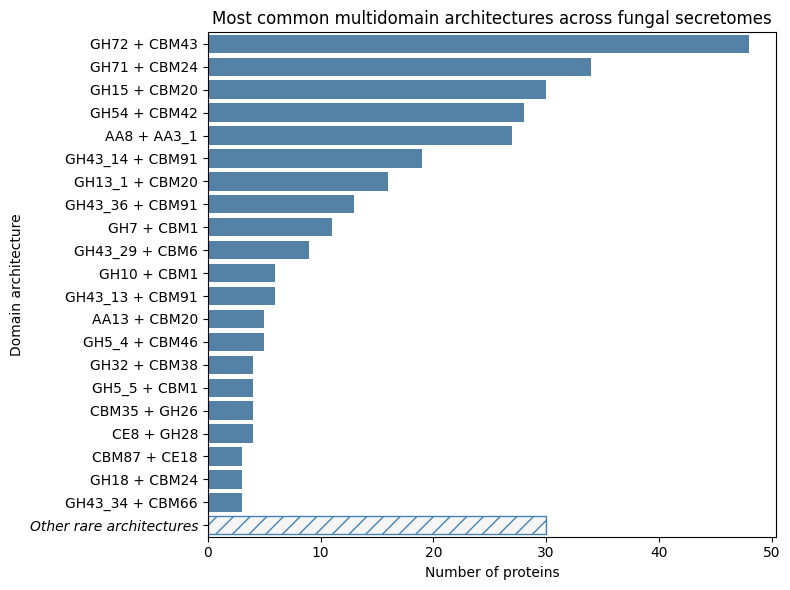

In [49]:
# Figure 2 — Most Common Multidomain Architectures
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = architecture_summary.copy()

colors = ["steelblue"] * len(arch_counts_plot)
colors[-1] = "lightgray"

plt.figure(figsize=(8,6))

sns.barplot(
    x=arch_counts_plot.values,
    y=arch_counts_plot.index,
    palette=colors,
    hue=arch_counts_plot.index,
    legend=False
)

ax = plt.gca()

ax.get_yticklabels()[-1].set_style("italic")
#ax.get_yticklabels()[-1].set_color("dimgray")

plt.xlabel("Number of proteins")
plt.ylabel("Domain architecture")
plt.title("Most common multidomain architectures across fungal secretomes")

plt.tight_layout()

ax.patches[-1].set_facecolor("whitesmoke")
ax.patches[-1].set_edgecolor("steelblue")
ax.patches[-1].set_hatch("//")


plt.savefig(
    "../results/figures/multidomain_architecture_frequency.png",
    dpi=300
)

plt.show()

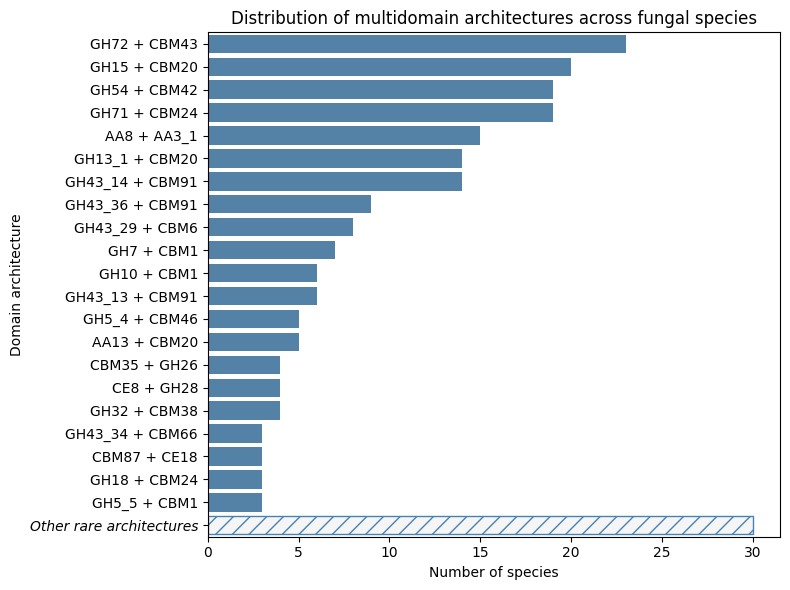

In [50]:
#Figure 3 — Most Widespread Architecturesplt.figure(figsize=(8,6))


colors = ["steelblue"] * len(arch_counts_plot)
colors[-1] = "lightgray"

plt.figure(figsize=(8,6))

sns.barplot(
    x=species_counts_plot.values,
    y=species_counts_plot.index,
    palette=colors,
    hue=arch_counts_plot.index,
    legend=False
)

ax = plt.gca()

ax.get_yticklabels()[-1].set_style("italic")
#ax.get_yticklabels()[-1].set_color("dimgray")

plt.xlabel("Number of species")
plt.ylabel("Domain architecture")
plt.title("Distribution of multidomain architectures across fungal species")

ax.patches[-1].set_facecolor("whitesmoke")
ax.patches[-1].set_edgecolor("steelblue")
ax.patches[-1].set_hatch("//")

plt.tight_layout()

plt.savefig(
    "../results/figures/multidomain_architecture_species_distribution.png",
    dpi=300
)

plt.show()


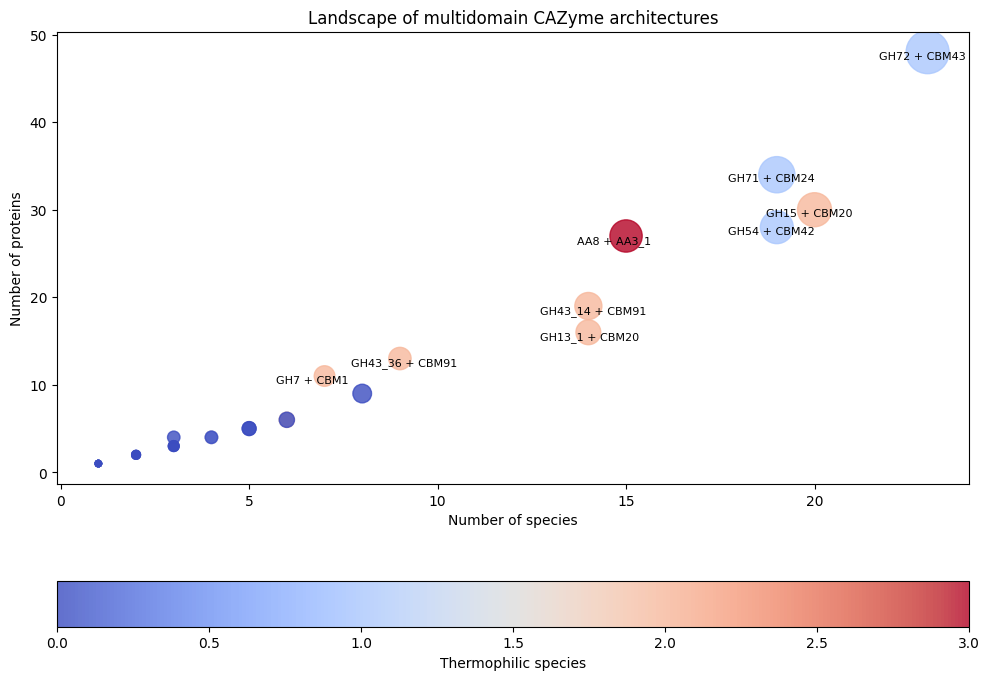

In [51]:
#Figure 4 — Architecture Landscape


plt.figure(figsize=(10,7))

scatter = plt.scatter(
    plot_df["species"],
    plot_df["proteins"],
    s=plot_df["proteins"] * 20,
    c=plot_df["thermophile_species"],
    cmap="coolwarm",
    alpha=0.8
)

label_df = plot_df[
    plot_df["proteins"] >= 10
]



for _, row in label_df.iterrows():

    plt.annotate(
        row["domain_architecture"],
        (row["species"], row["proteins"]),
        xytext=(-35,-5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Number of species")
plt.ylabel("Number of proteins")
#plt.yscale("log")

plt.title(
    "Landscape of multidomain CAZyme architectures"
)

plt.subplots_adjust(right=0.9)

#cbar = plt.colorbar(scatter)
#cbar.set_label("Thermophilic species")

cbar = plt.colorbar(
    scatter,
    orientation="horizontal",
    pad=0.15
)

cbar.set_label("Thermophilic species")

plt.tight_layout()

plt.savefig(
    "../results/figures/multidomain_architecture_landscape.png",
    dpi=300
)

plt.show()

In [52]:
print("Raw hits:", len(hits))
print("Filtered hits:", len(hits_filtered))
print("Merged hits:", len(hits_merged))

print(
    "Unique CAZyme proteins:",
    hits_merged["query"].nunique()
)

print(
    "Multidomain proteins:",
    multi_hetero["query"].nunique()
)

print(
    "Architecture types:",
    multi_hetero["domain_architecture"].nunique()
)

Raw hits: 17662
Filtered hits: 6363
Merged hits: 6315
Unique CAZyme proteins: 5971
Multidomain proteins: 312
Architecture types: 47
